# 01. Baseline: як декодери читають чисті коди

**Тиждень 1.** Перш ніж щось псувати й покращувати, перевіряємо, що всі три декодери
читають чисті коди, і розуміємо, що саме вони повертають.

- `opencv`: `cv2.barcode.BarcodeDetector`, лише EAN/UPC
- `wechat`: `cv2.wechat_qrcode_WeChatQRCode`, лише QR
- `zxing`: `zxing-cpp`, усі формати (EAN-13, Code128, QR)

In [1]:
import sys
from pathlib import Path

# ноутбук лежить у notebooks/, корінь проєкту на рівень вище
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))
RESULTS = PROJECT_ROOT / "results"
RESULTS.mkdir(exist_ok=True)

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)

In [2]:
from src.data import generate_synthetic, render_code, camera_look, load_own_photos
from src.decoders import DECODERS, decoders_for

N_PER_FORMAT = 10   # кодів кожного формату
samples = generate_synthetic(n_per_format=N_PER_FORMAT, seed=42)
print("Зразків:", len(samples))

Зразків: 30


## Як виглядають синтетичні коди

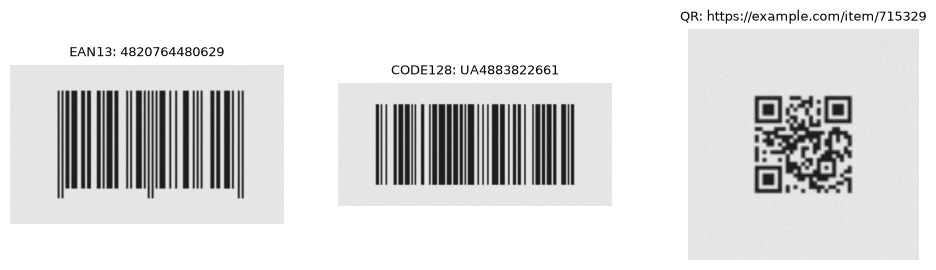

In [3]:
examples = [samples[0], samples[N_PER_FORMAT], samples[2 * N_PER_FORMAT]]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, sample in zip(axes, examples):
    ax.imshow(sample["image"], cmap="gray", vmin=0, vmax=255)
    ax.set_title(sample["format"] + ": " + sample["text"], fontsize=9)
    ax.axis("off")
plt.show()

## Що повертає кожен декодер

Результат кожного декодера у `src/decoders.py` зведено до одного формату:
список словників `{"text": ..., "format": ...}`. Порожній список означає «нічого не прочитано».

In [4]:
sample = samples[0]
for name in decoders_for(sample["format"]):
    print(name, "->", DECODERS[name](sample["image"]))

opencv -> [{'text': '4820764480629', 'format': 'EAN13'}]
zxing -> [{'text': '4820764480629', 'format': 'EAN13'}]


## Частка прочитаних чистих кодів

In [5]:
from src.evaluate import run_benchmark

# levels=[] -> лише чисті кадри (рівень 0), метод raw = без обробки
clean_table = run_benchmark(samples, methods=["raw"], levels=[])
clean_table["correct"] = clean_table["outcome"] == "correct"
clean_table.pivot_table(index="format", columns="decoder", values="correct", aggfunc="mean")

/Users/andriizemlianyi/venvs/cv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


benchmark:   0%|          | 0/30 [00:00<?, ?it/s]

benchmark: 100%|██████████| 30/30 [00:00<00:00, 682.76it/s]

decoder,opencv,wechat,zxing
format,,,
CODE128,NaN,NaN,1.0
EAN13,1.0,NaN,1.0
QR,NaN,1.0,1.0


## Несподіванка: ідеально різкий код OpenCV не бачить

Знайдено на початку проєкту. Тому `generate_synthetic` пропускає кожен код через
`camera_look` (реальні рівні 30/230, легке розмиття, шум).

In [6]:
perfect = render_code(samples[0]["text"], "EAN13", module_px=4)
camera = camera_look(perfect)
for title, image in [("ідеальний", perfect), ("camera_look", camera)]:
    print(title, "opencv:", DECODERS["opencv"](image), "zxing:", DECODERS["zxing"](image))

ідеальний opencv: [] zxing: [{'text': '4820764480629', 'format': 'EAN13'}]
camera_look opencv: [{'text': '4820764480629', 'format': 'EAN13'}] zxing: [{'text': '4820764480629', 'format': 'EAN13'}]


## Твої фото (коли будуть)

Поклади фото в `data/raw/own/` і заповни `labels.csv` (див. README).
TODO: порівняти частку прочитаних на твоїх фото при `normal` з синтетикою.

In [7]:
own = load_own_photos()
if own:
    own_table = run_benchmark(own, methods=["raw"], levels=[])
    own_table["light"] = own_table["sample"].str.rsplit("_", n=1).str[1]
    own_table["correct"] = own_table["outcome"] == "correct"
    print(own_table.pivot_table(index="light", columns="decoder", values="correct", aggfunc="mean"))

Немає /Users/andriizemlianyi/Code/zemand-learning/Computer Vision/r_d/r_d-computer-vision-project/data/raw/own/labels.csv - пропускаю власні фото
